In [31]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [32]:
d1 = find_file("240220_TempoSO4_W3_run2.DSC", exp_type="francklab_esr/romana") #W3 heating 1
d2 = find_file("240220_TempoSO4_W20_run2.DSC", exp_type="francklab_esr/romana") #W20 heating

In [33]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (10, 'harmonic')]

In [34]:
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [35]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [36]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

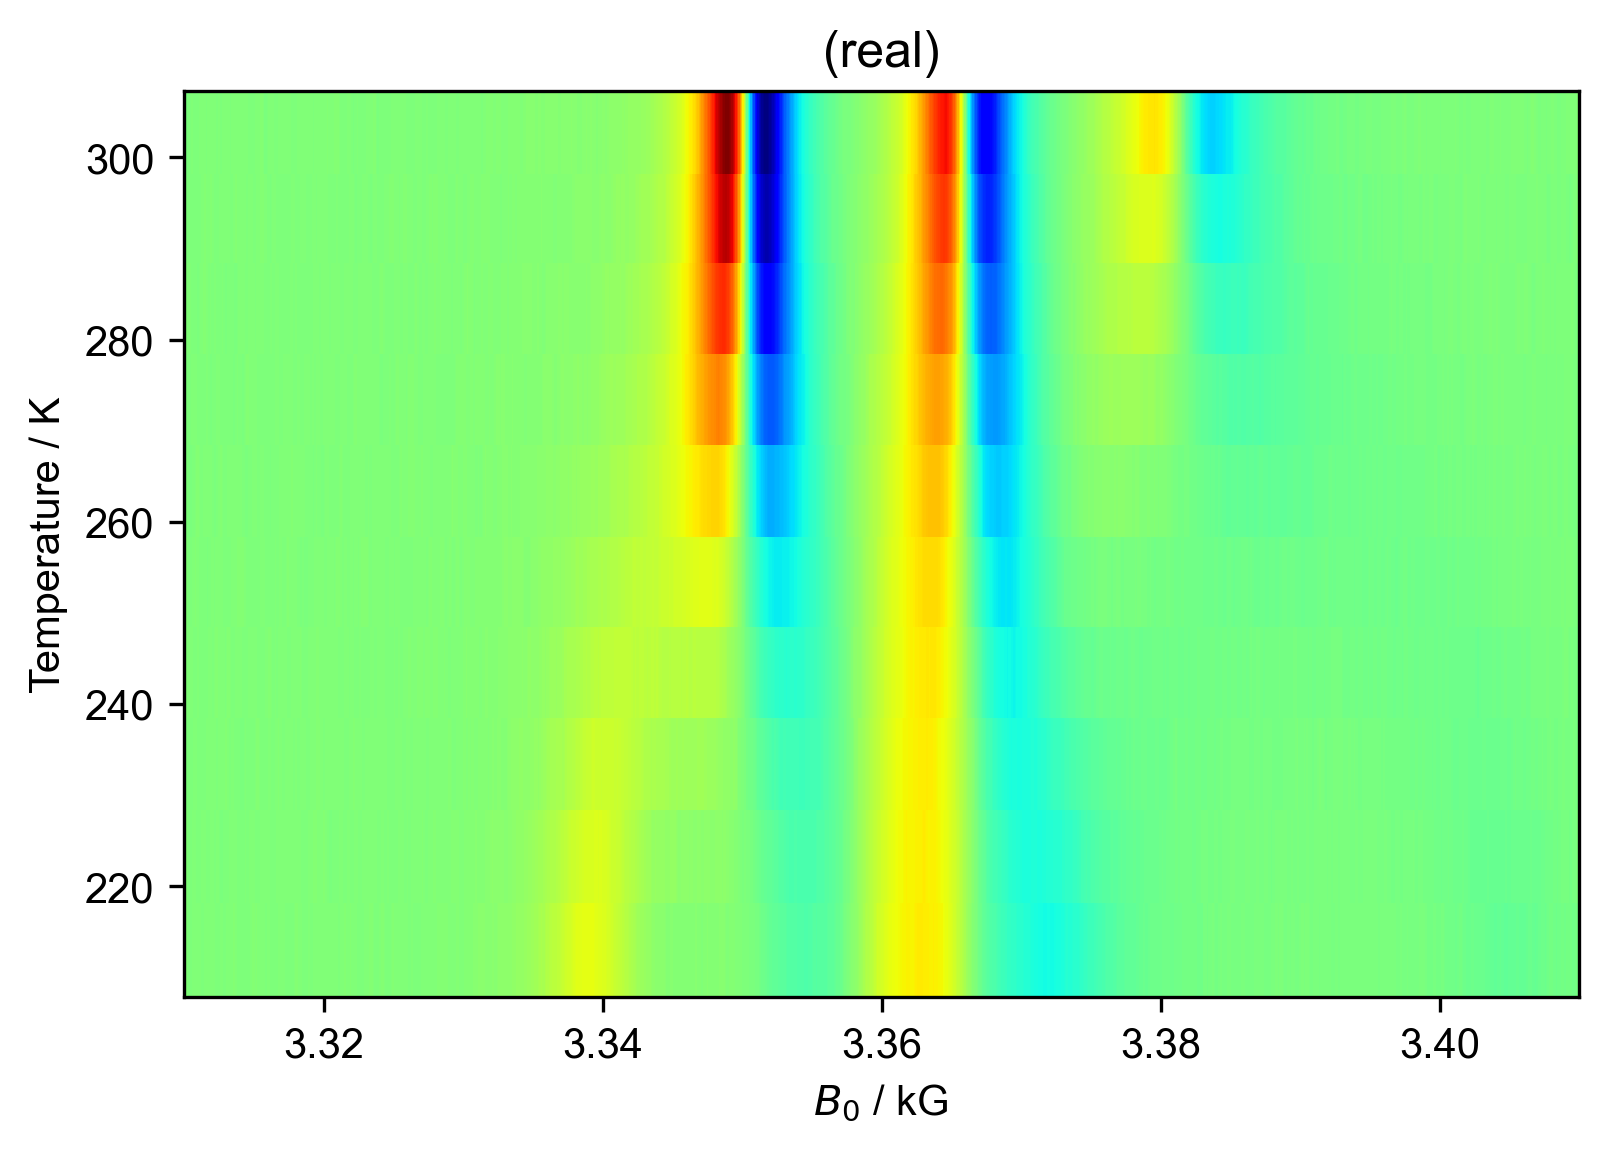

In [37]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()

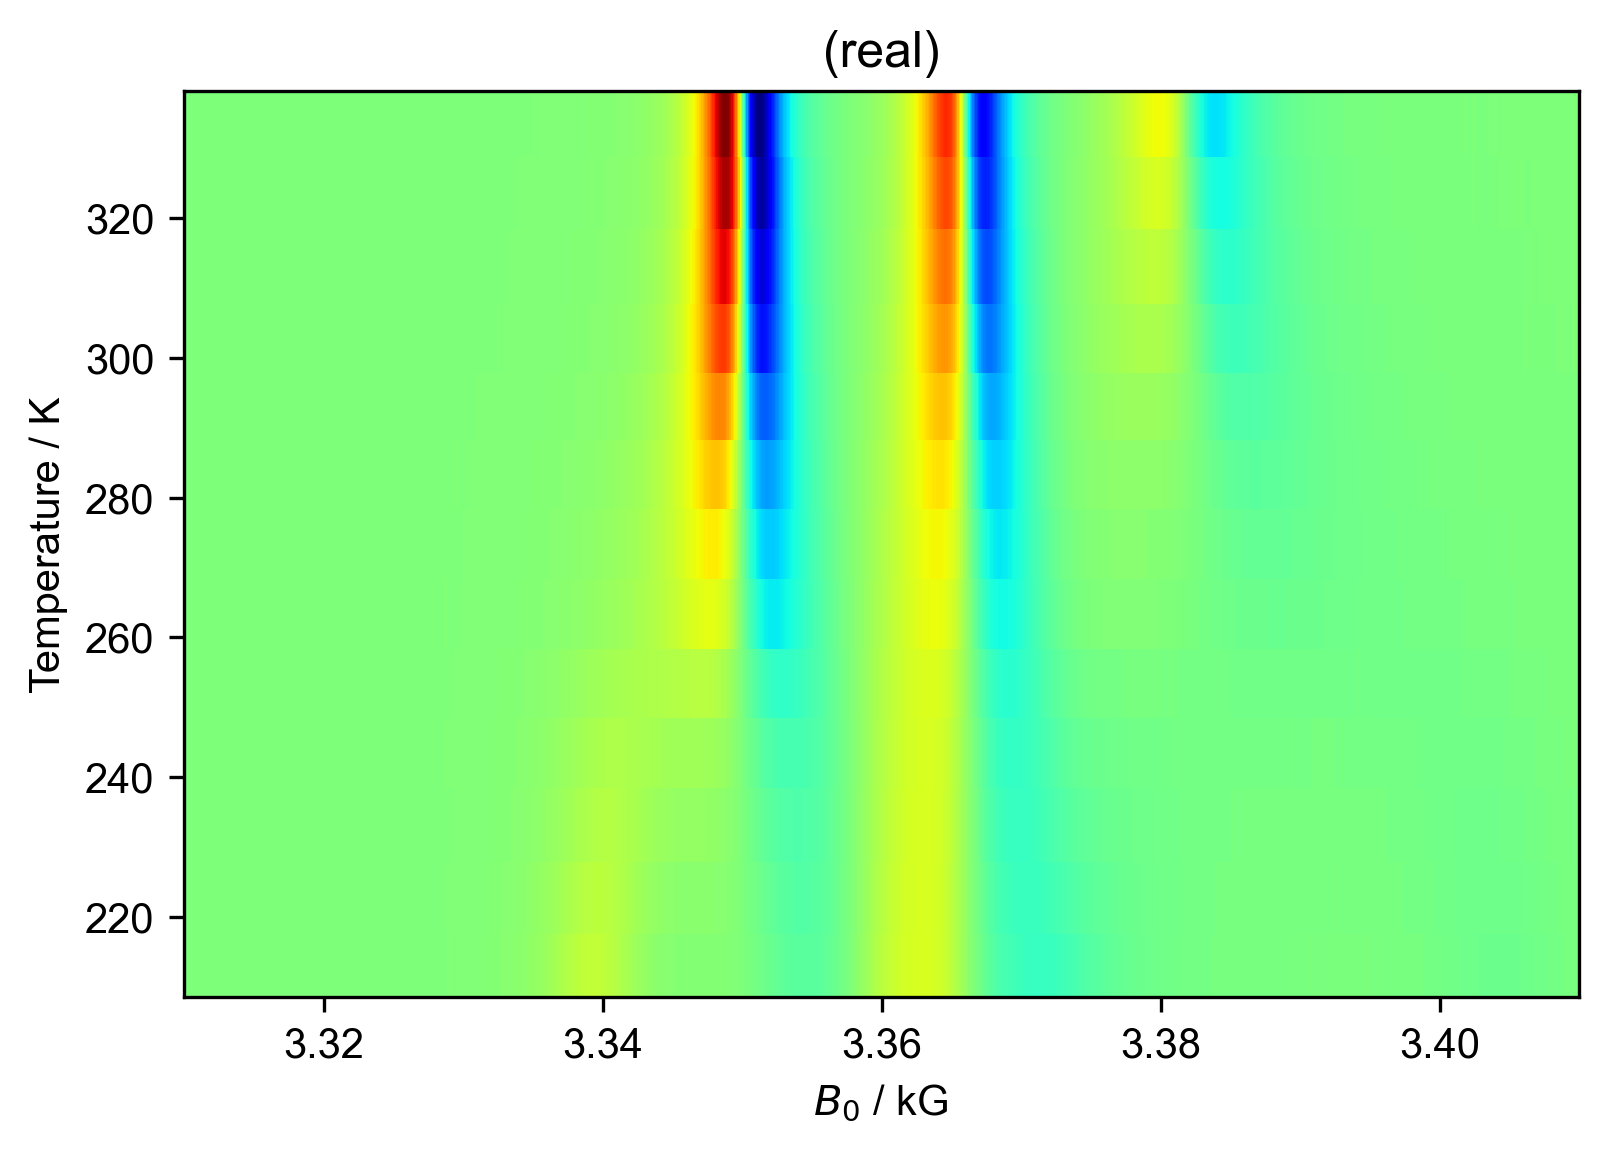

In [38]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()

From this, I learn that
it's easiest to show the 1D plots above and below the transition

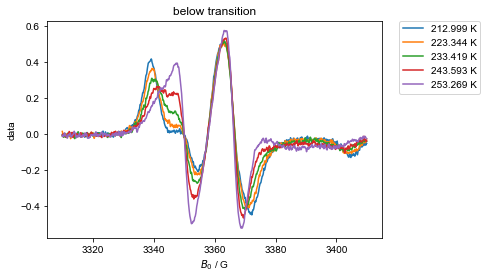

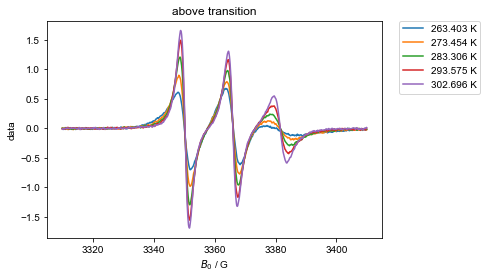

In [39]:
#w3
for this_label, temp_range in [
    ("below transition", (None, 257.8)),
    ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

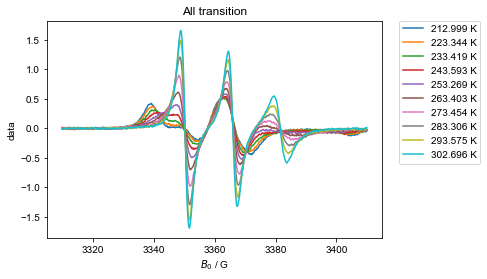

In [40]:
#w3 same plot
for this_label, temp_range in [
    ("All transition", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

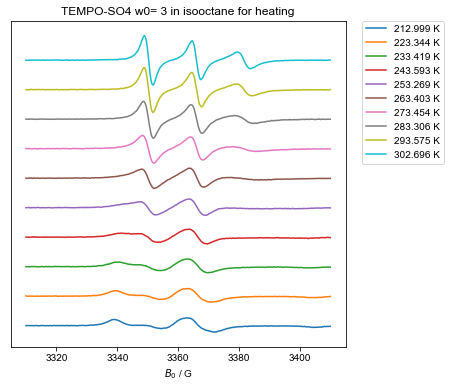

In [41]:
#w3 same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO4 w0= 3 in isooctane for heating", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure(figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 2
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

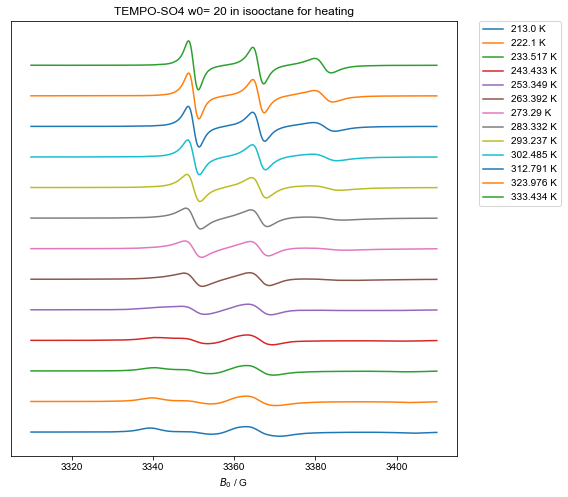

In [42]:
#w20 same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO4 w0= 20 in isooctane for heating", (173, 373))
 ]:
    this_d2 = d2["Temperature":temp_range]
    figure(figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

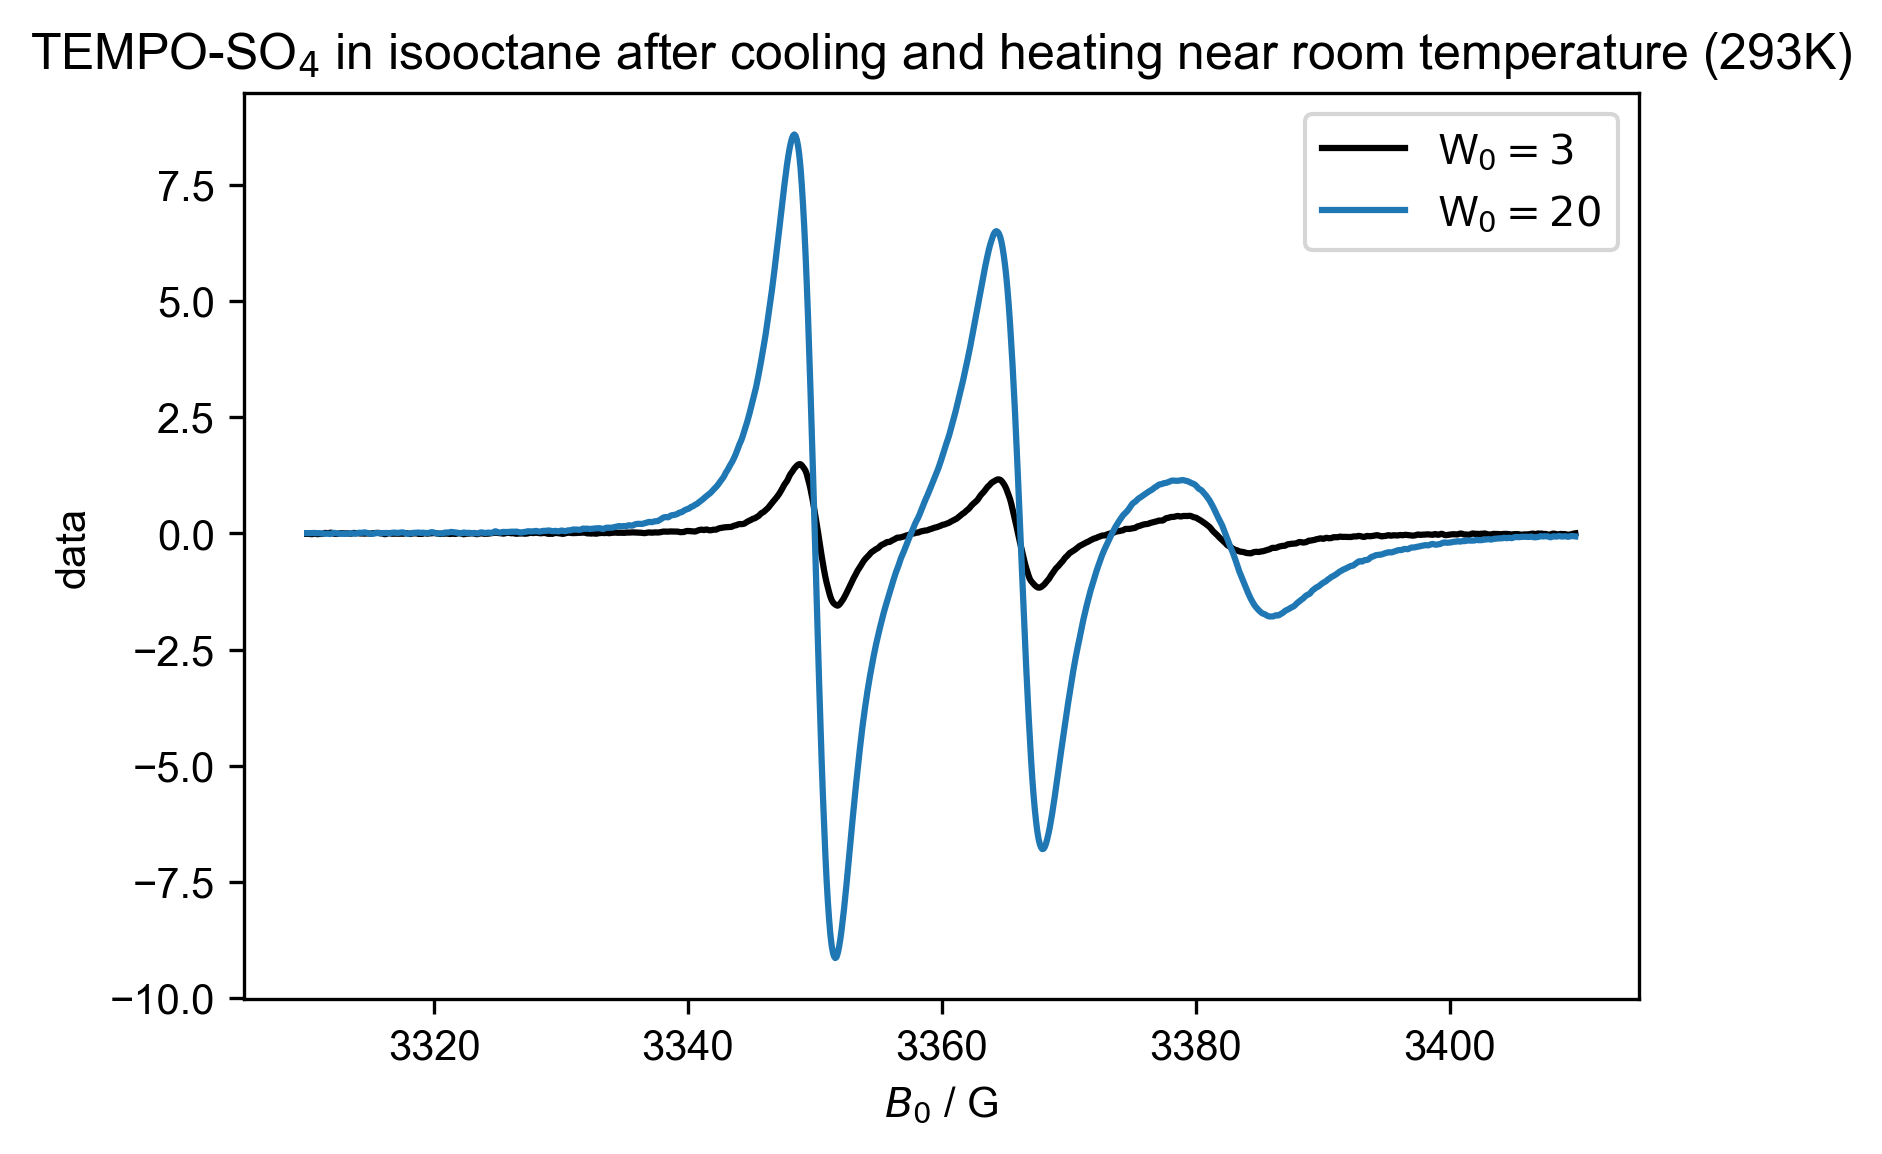

In [43]:
#near room temperature
#print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":293.5], label="W$_0=3$", color="black")
plot(d2["Temperature":293.237], label="W$_0=20$")
title("TEMPO-SO$_4$ in isooctane after cooling and heating near room temperature (293K)")
legend()

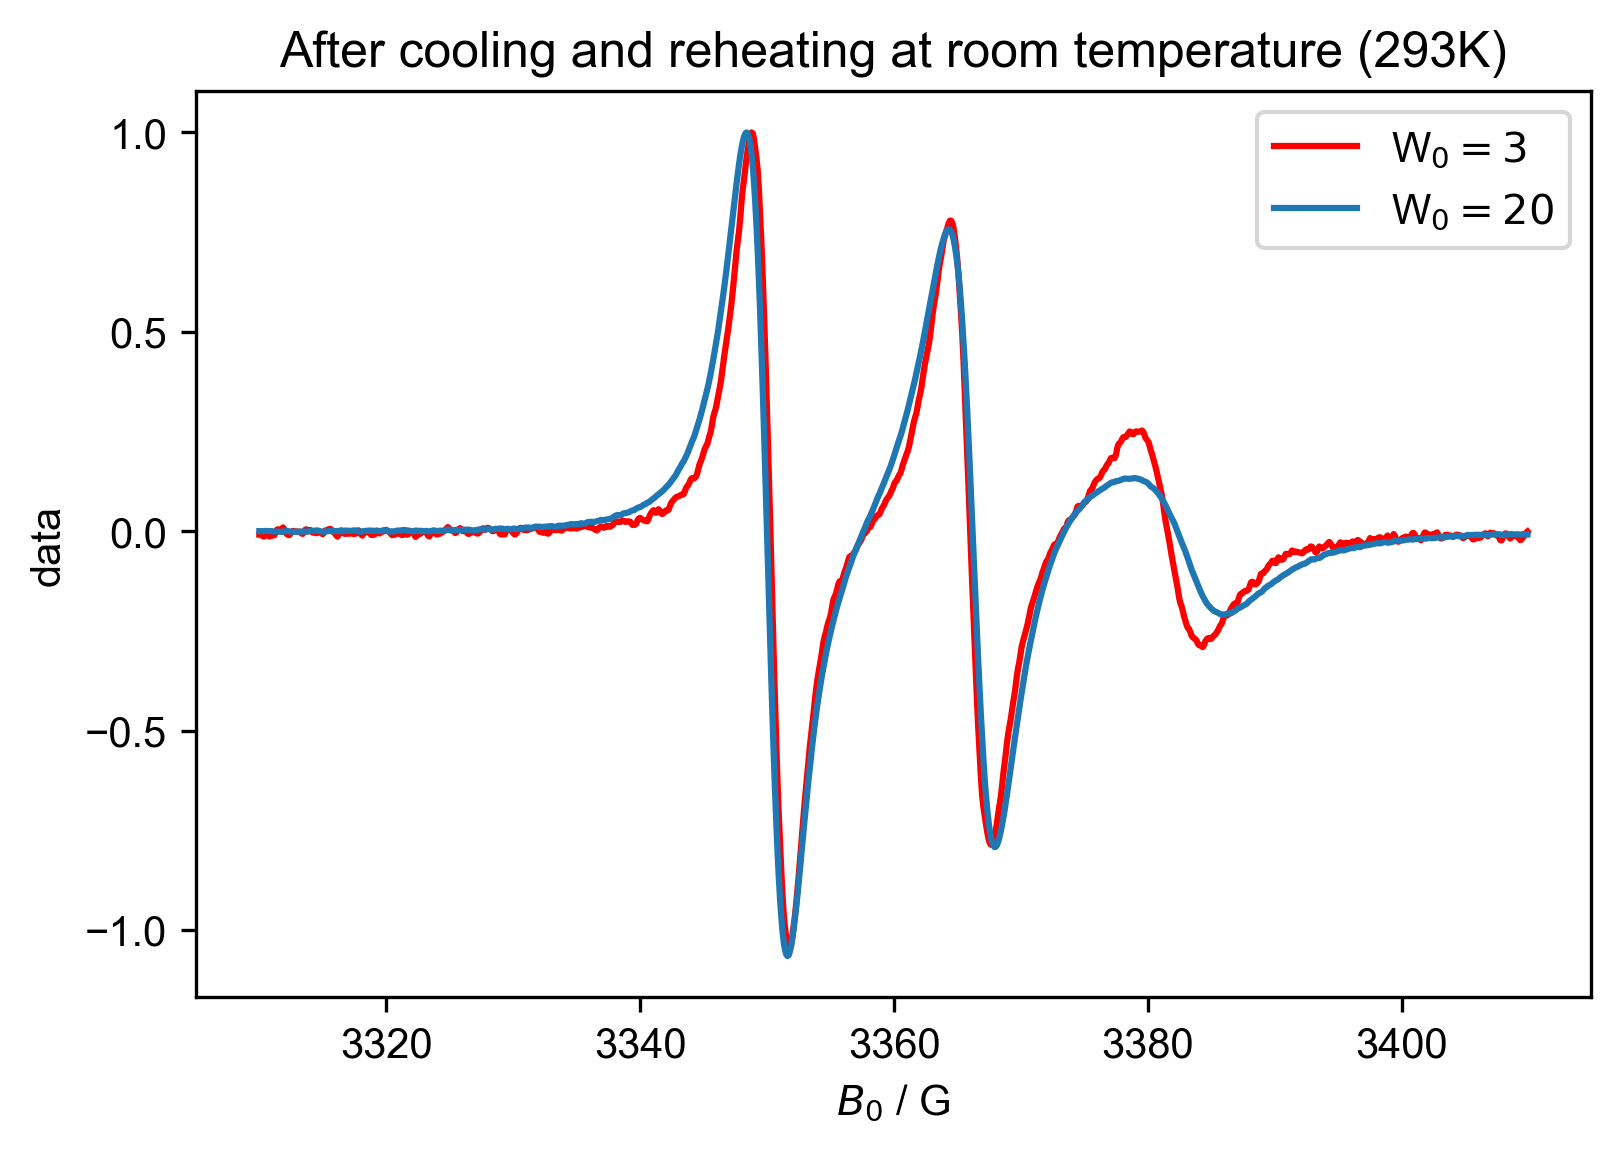

In [44]:
#Normalized
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "W$_0=3$", color="red")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "W$_0=20$")
title("After cooling and reheating at room temperature (293K)")
legend()

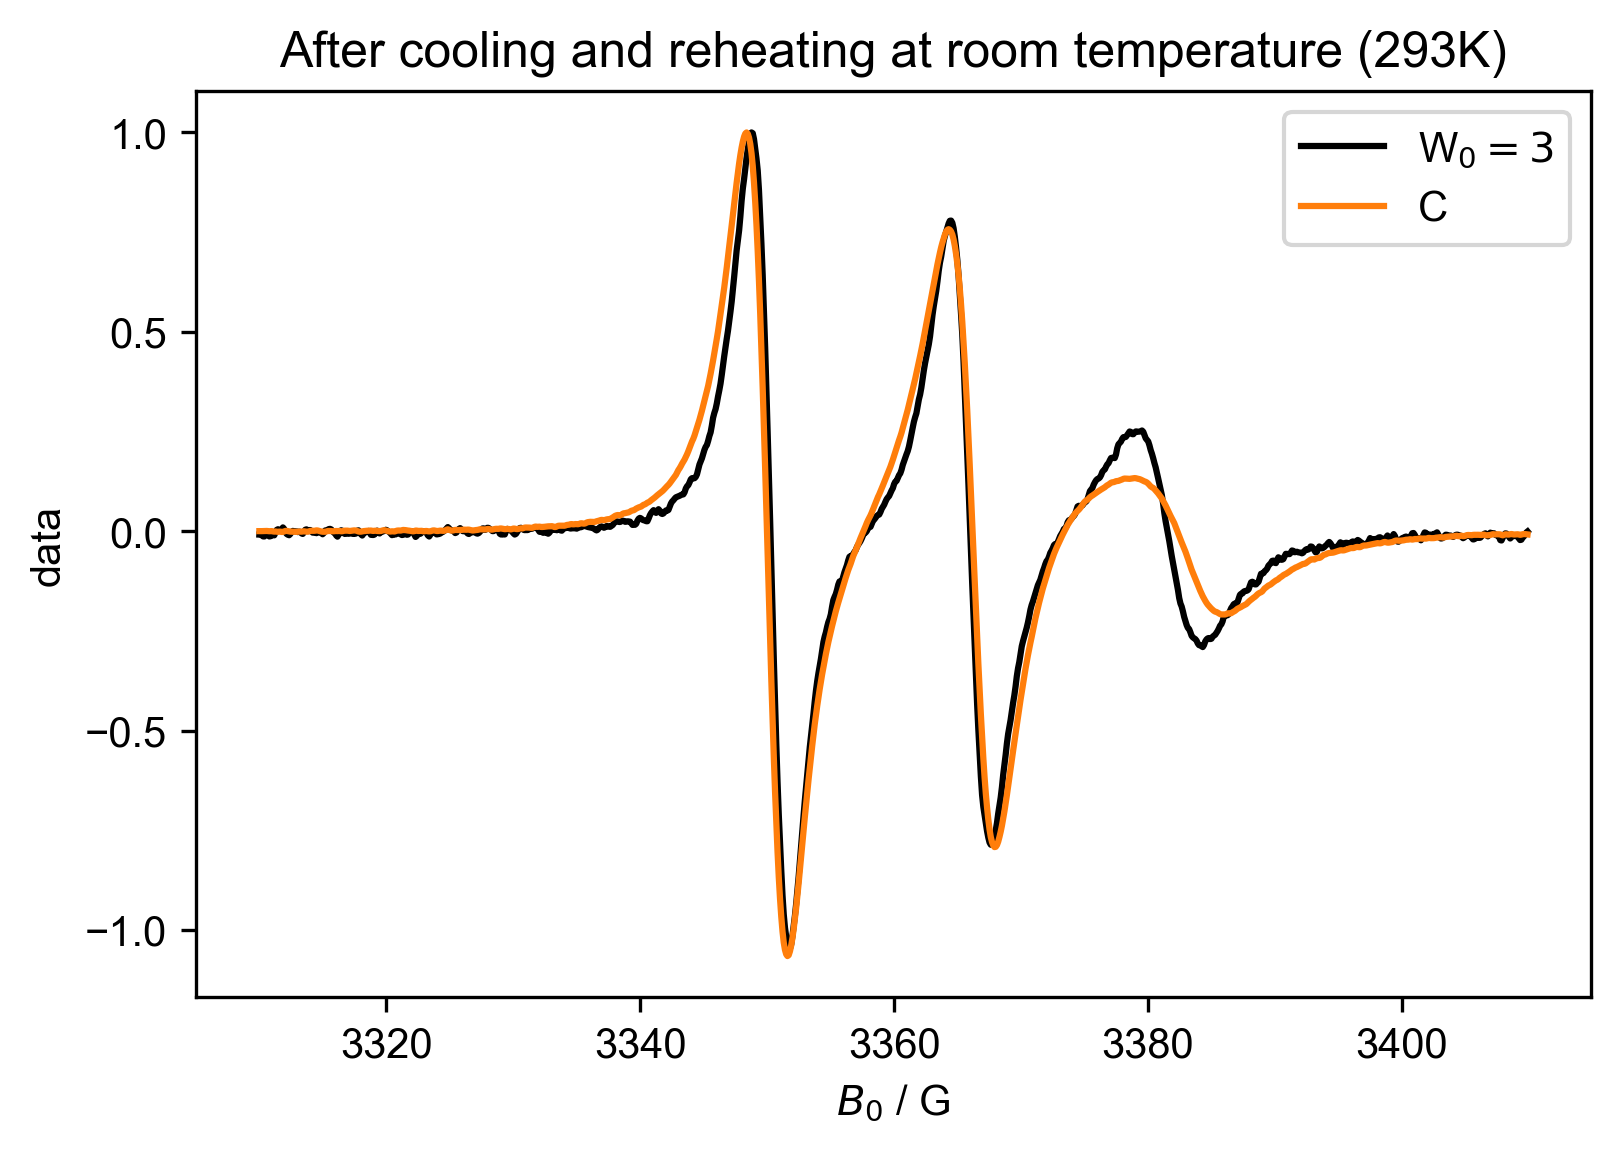

In [45]:
#Normalized
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "W$_0=3$", color="black")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "C", color="#FF7E0B")
title("After cooling and reheating at room temperature (293K)")
legend()

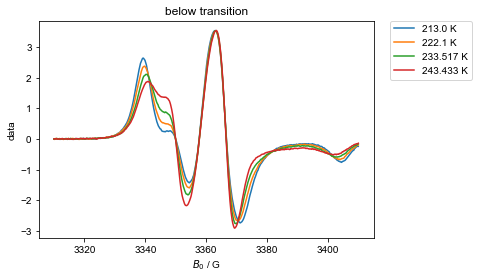

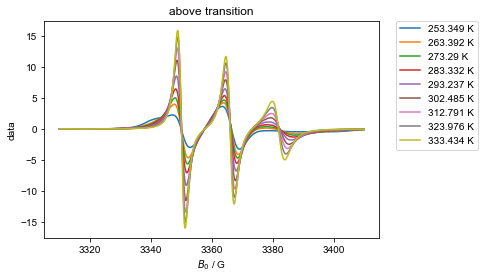

In [46]:
#heating run2
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

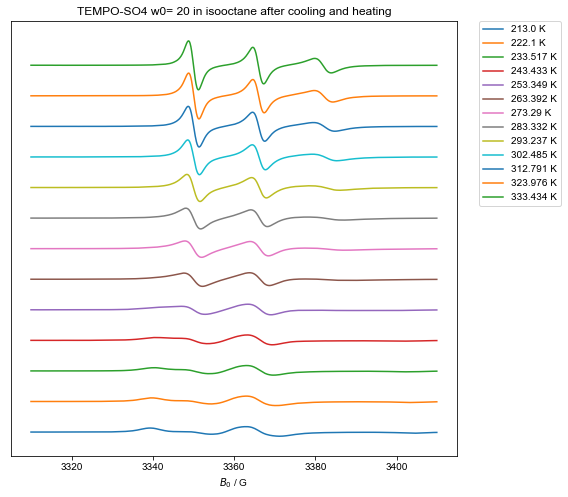

In [47]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO4 w0= 20 in isooctane after cooling and heating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

## adding w3 reheating 2 

In [48]:
d3 = find_file("240220_TempoSO4_W3_run3.DSC", exp_type="francklab_esr/romana") #W3 heating 2

In [49]:
d3.shape

[(1024, '$B_0$'), (7, 'Temperature'), (10, 'harmonic')]

In [50]:
d3.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d3.shape 

[(1024, '$B_0$'), (7, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

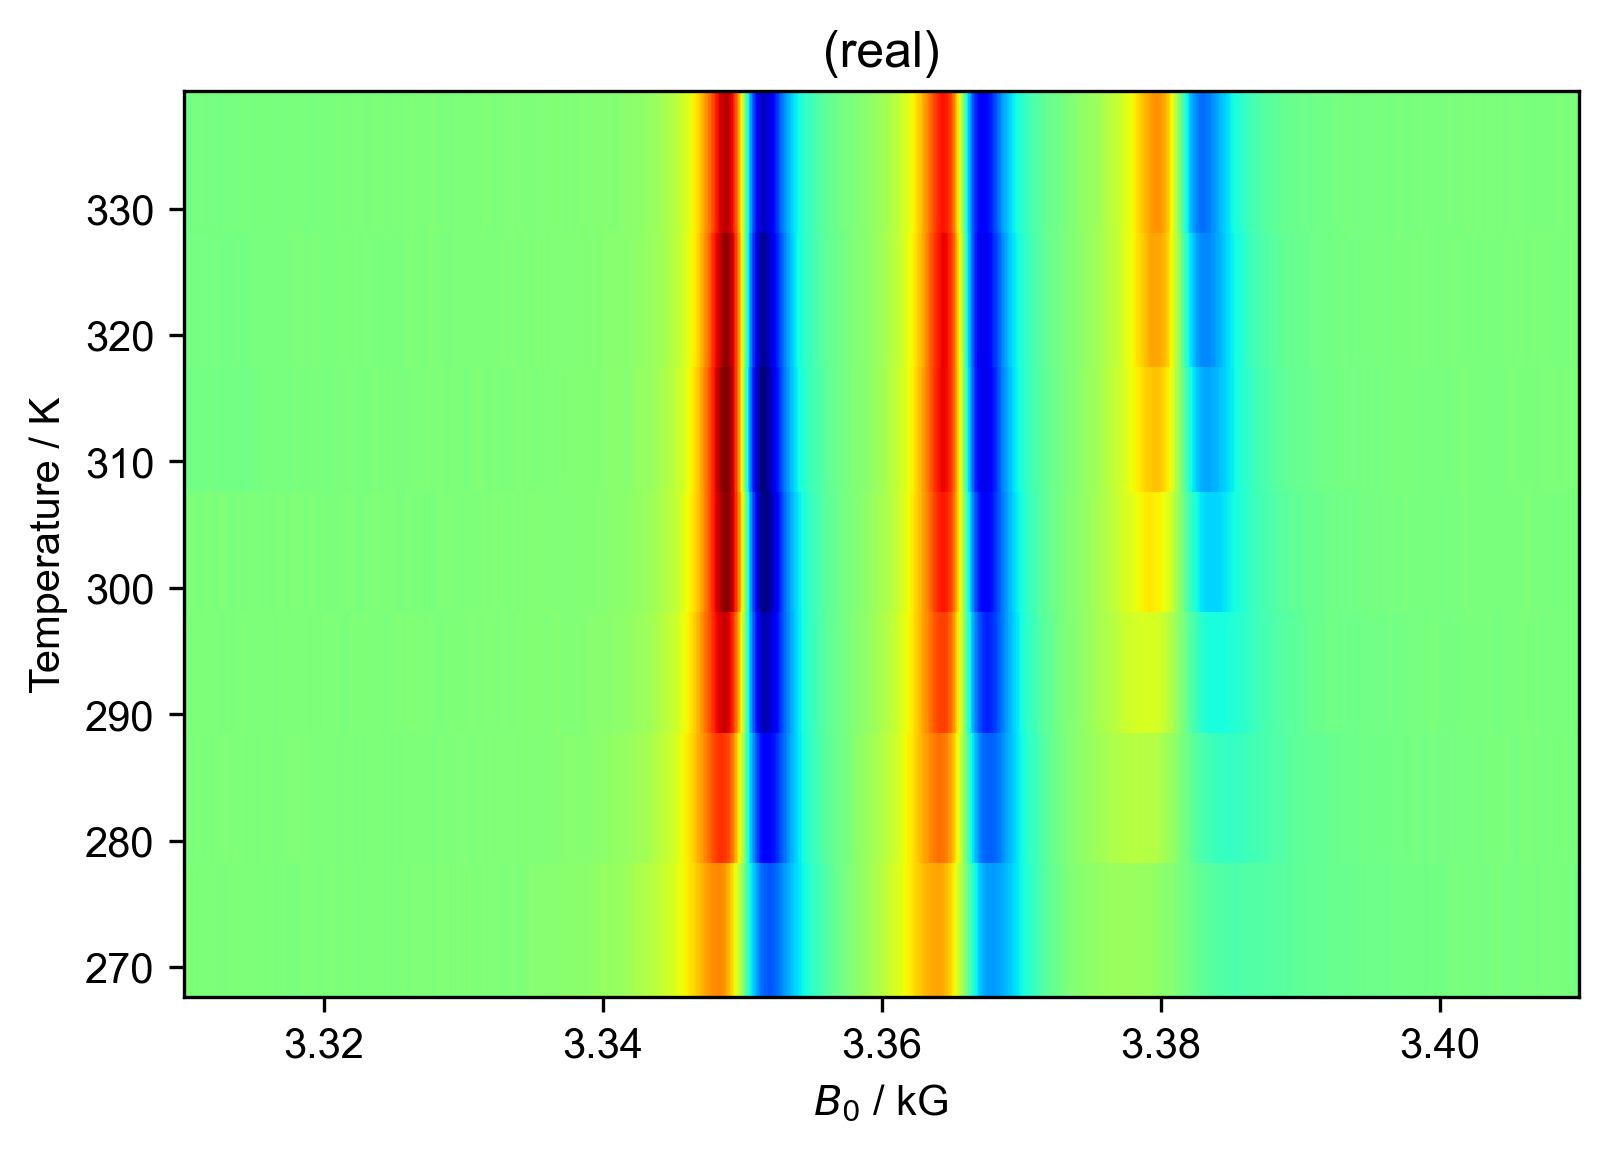

In [51]:
figure(dpi=300)
d3 = d3["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d3.sort('Temperature')
d3.reorder("Temperature").pcolor()

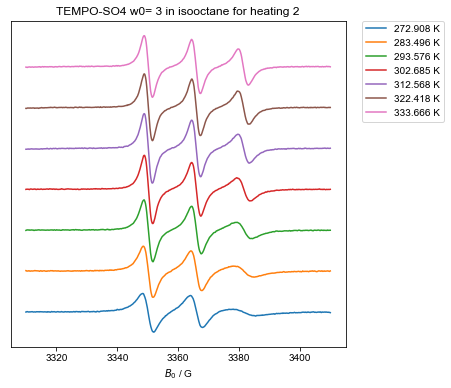

In [52]:
#w3 same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO4 w0= 3 in isooctane for heating 2", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d3 = d3["Temperature":temp_range]
    figure(figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d3.shape["Temperature"]):
        this_temp = this_d3.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d3["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 2
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

[272.908 283.496 293.576 302.685 312.568 322.418 333.666]
[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


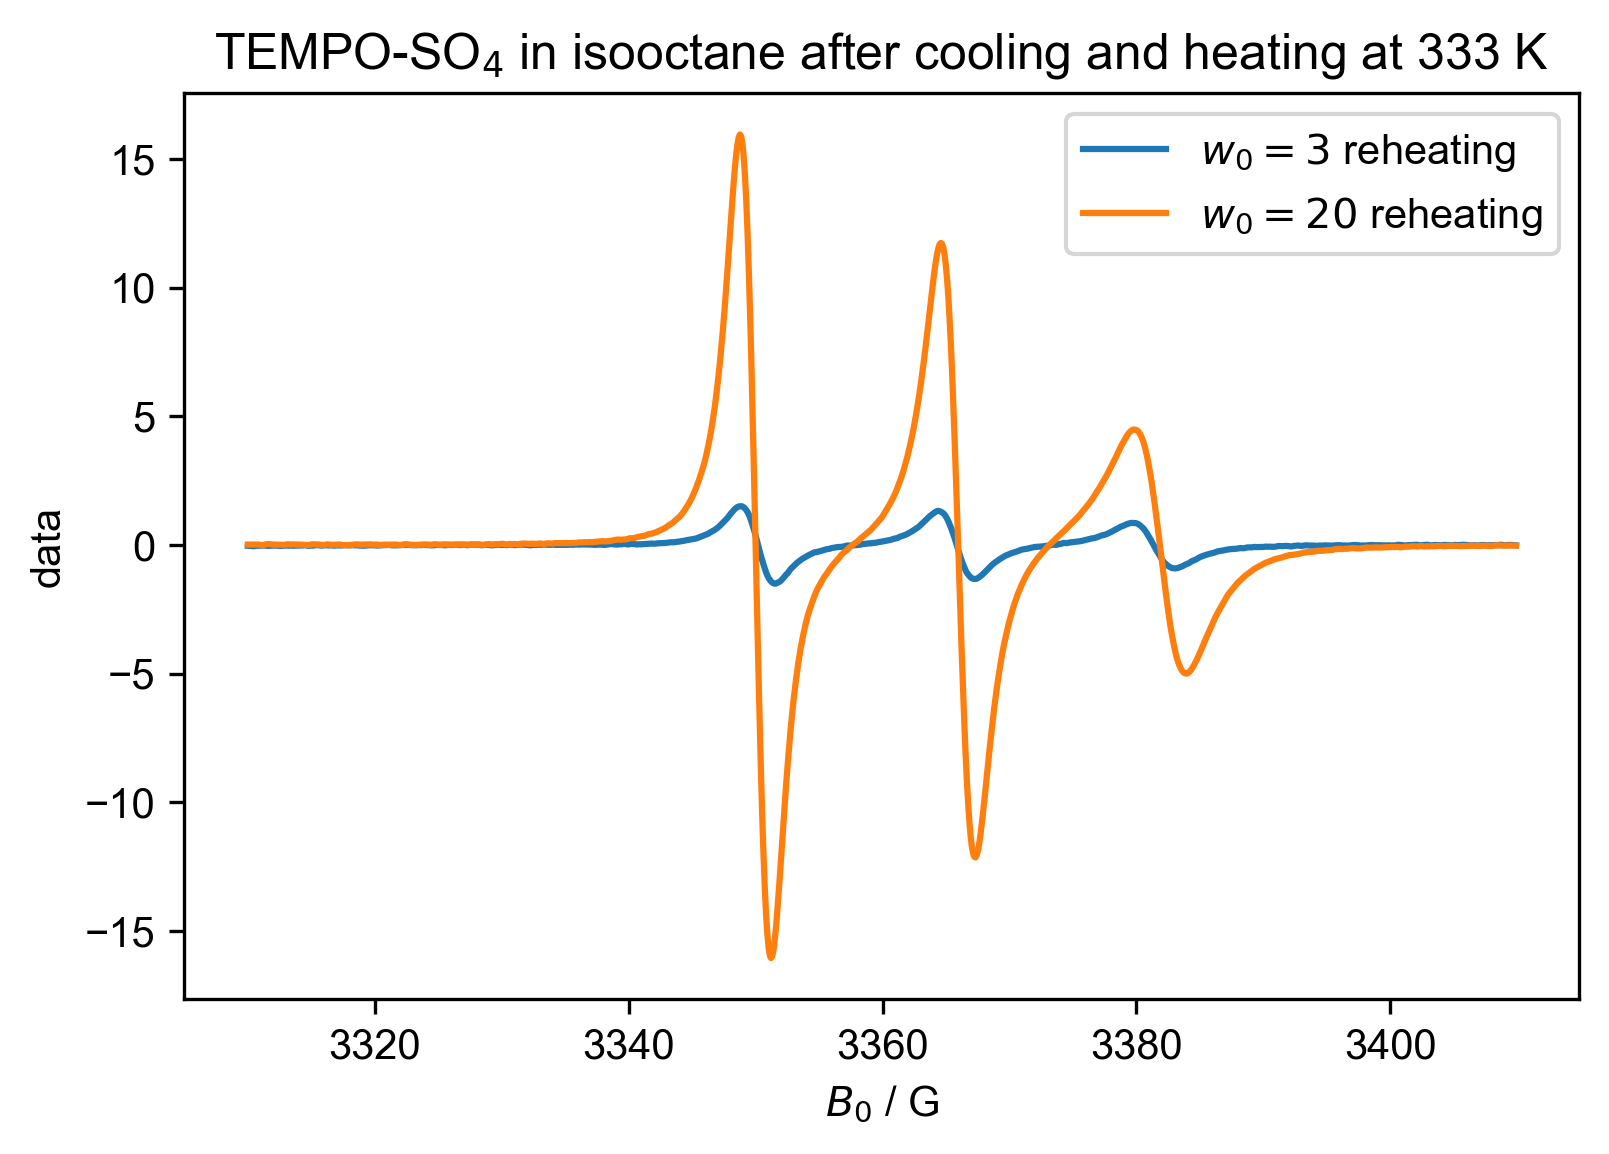

In [54]:
print(d3.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d3["Temperature":333], label="$w_0=3$ reheating")
plot(d2["Temperature":333], label="$w_0=20$ reheating")
title("TEMPO-SO$_4$ in isooctane after cooling and heating at 333 K")
legend()

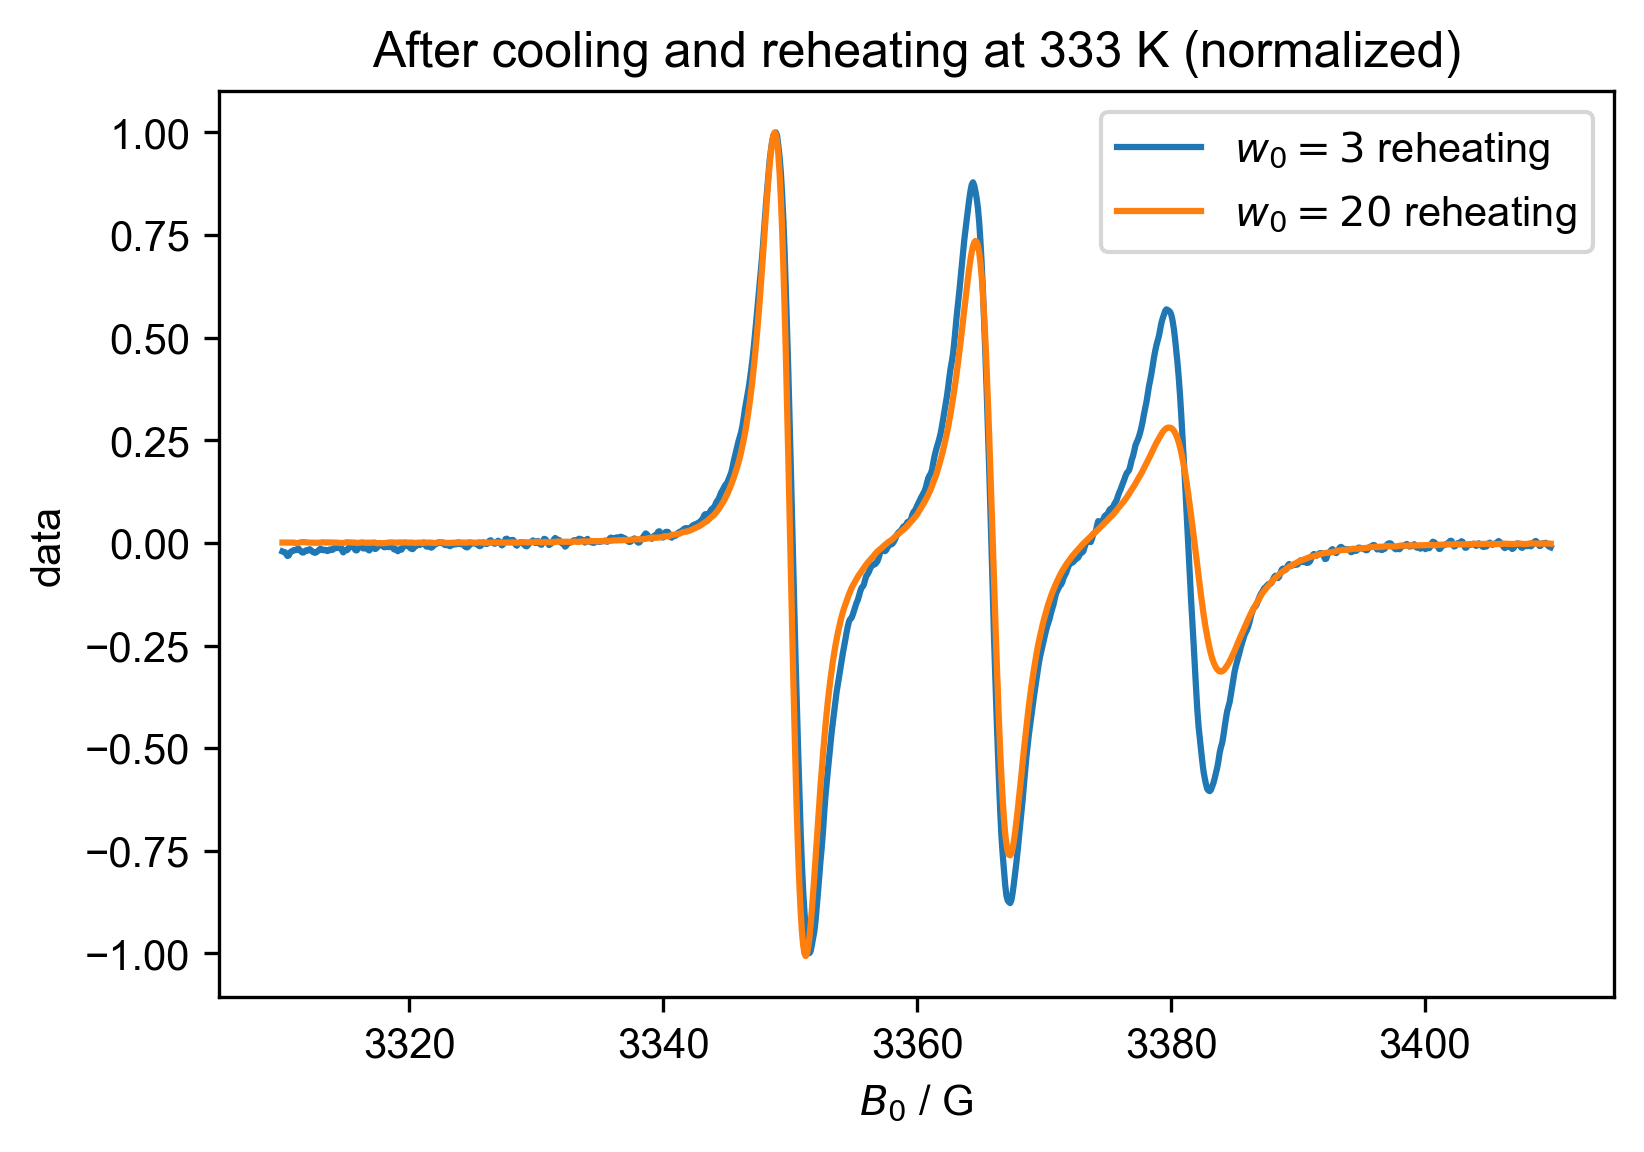

In [55]:
#Normalized
figure(dpi=300, figsize=(6,4))
plot(d3["Temperature": 333] / d3["Temperature": 333].max(), label= "$w_0=3$ reheating")
plot(d2["Temperature": 333] / d2["Temperature": 333].max(), label= "$w_0=20$ reheating")
title("After cooling and reheating at 333 K (normalized)")
legend()